# Call graph gallery

This notebook draws layout cases for `draw_call_graph`. `draw_call_graph` lays out the graph with Graphviz `dot`.

CI does not run this notebook. The saved outputs are for viewing on GitHub. Re-run the notebook and commit the outputs after you change `draw_call_graph` or `CallGraphEvaluatorHooks`.

In [ ]:
from collections.abc import Sequence
from typing import Optional

from quri_parts.qsub.compile import compile
from quri_parts.qsub.eval import CallGraphEvaluatorHooks, SubwiseProfileEvaluatorHooks
from quri_parts.qsub.evaluate import Evaluator
from quri_parts.qsub.lib import std
from quri_parts.qsub.namespace import NameSpace
from quri_parts.qsub.op import Ident
from quri_parts.qsub.opsub import ParamUnitarySubDef, UnitarySubDef, opsub, param_opsub
from quri_parts.qsub.register import QRegSpec
from quri_parts.qsub.sub import SubBuilder
from quri_parts.qsub.visualize import draw_call_graph

NS = NameSpace("cg")
Graph = dict[Optional[Ident], dict[Ident, int]]


def nodes(names: str) -> tuple[Ident, ...]:
    return tuple(Ident(NS, n) for n in names.split())


def draw_compiled(op, primitives, gates=None):
    compiled = compile(op, primitives)
    graph = Evaluator(CallGraphEvaluatorHooks()).run(compiled)
    hooks = (
        SubwiseProfileEvaluatorHooks(gates=gates)
        if gates
        else SubwiseProfileEvaluatorHooks()
    )
    profile = Evaluator(hooks).run(compiled)
    return draw_call_graph(graph, profile)

## 1. Review case: C → A alongside C → B → A

C → A must not cross B or run along the C → B / B → A arrows.

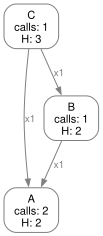

In [ ]:
class _A(UnitarySubDef):
    name = "A"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(std.H, b.qubits)


A, _ = opsub(_A)


class _B(UnitarySubDef):
    name = "B"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(std.H, b.qubits)
        b.add_op(A, b.qubits)


B, _ = opsub(_B)


class _C(UnitarySubDef):
    name = "C"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(A, b.qubits)
        b.add_op(B, b.qubits)


C, _ = opsub(_C)

draw_compiled(C, (std.H,))

## 2. Plain chain with repeated calls

`x2` / `x3` highlighted in red.

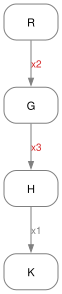

In [ ]:
R, G, H, K = nodes("R G H K")
draw_call_graph({R: {G: 2}, G: {H: 3}, H: {K: 1}, K: {}})

## 3. Fan-out and fan-in (diamond)

Several nodes per layer; edges between adjacent layers only.

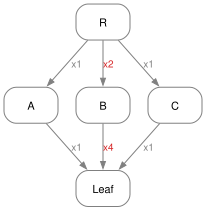

In [ ]:
R, A, B, C, L = nodes("R A B C Leaf")
draw_call_graph({R: {A: 1, B: 2, C: 1}, A: {L: 1}, B: {L: 4}, C: {L: 1}, L: {}})

## 4. Parametric recursion with a shortcut

`Chain<k>` recurses and `Chain<3>` also calls `Leaf` directly; nodes carry profile labels.

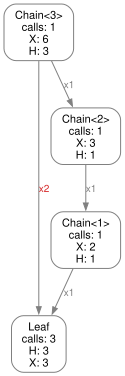

In [ ]:
class _Leaf(UnitarySubDef):
    name = "Leaf"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(std.X, b.qubits)
        b.add_op(std.H, b.qubits)


Leaf, _ = opsub(_Leaf)


class _Chain(ParamUnitarySubDef[int]):
    name = "Chain"

    def qubit_count_fn(self, k: int) -> int:
        return 1

    def qregs_fn(self, k: int) -> Sequence[QRegSpec]:
        return (QRegSpec("q", 1),)

    def sub(self, b: SubBuilder, k: int) -> None:
        (q,) = b.qregs["q"].qubits
        b.add_op(std.X, (q,))
        if k == 3:
            b.add_op(Leaf, (q,))
            b.add_op(Leaf, (q,))
        if k > 1:
            b.add_op(Chain(k - 1), (q,))
        else:
            b.add_op(Leaf, (q,))


Chain, _ = param_opsub(_Chain)

draw_compiled(Chain(3), (std.X, std.H))

## 5. Wide boxes (long names, several gate kinds)

Check that edges clear wide boxes and labels stay readable.

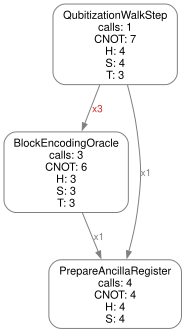

In [ ]:
class _PrepareAncillaRegister(UnitarySubDef):
    name = "PrepareAncillaRegister"
    qubit_count = 2

    def sub(self, b: SubBuilder) -> None:
        q0, q1 = b.qubits
        b.add_op(std.H, (q0,))
        b.add_op(std.S, (q1,))
        b.add_op(std.CNOT, (q0, q1))


PrepareAncillaRegister, _ = opsub(_PrepareAncillaRegister)


class _BlockEncodingOracle(UnitarySubDef):
    name = "BlockEncodingOracle"
    qubit_count = 2

    def sub(self, b: SubBuilder) -> None:
        q0, q1 = b.qubits
        b.add_op(PrepareAncillaRegister, (q0, q1))
        b.add_op(std.T, (q0,))
        b.add_op(std.CNOT, (q1, q0))


BlockEncodingOracle, _ = opsub(_BlockEncodingOracle)


class _QubitizationWalkStep(UnitarySubDef):
    name = "QubitizationWalkStep"
    qubit_count = 2

    def sub(self, b: SubBuilder) -> None:
        for _ in range(3):
            b.add_op(BlockEncodingOracle, b.qubits)
        b.add_op(PrepareAncillaRegister, b.qubits)


QubitizationWalkStep, _ = opsub(_QubitizationWalkStep)

draw_compiled(QubitizationWalkStep, (std.H, std.S, std.T, std.CNOT))

## 6. Local-name collision across namespaces

Two subs named `F` get fully qualified labels.

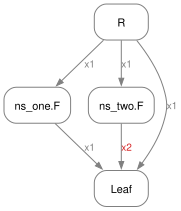

In [ ]:
R = Ident(NS, "R")
F1, F2 = Ident(NameSpace("ns_one"), "F"), Ident(NameSpace("ns_two"), "F")
L = Ident(NS, "Leaf")
draw_call_graph({R: {F1: 1, F2: 1, L: 1}, F1: {L: 1}, F2: {L: 2}, L: {}})

## 7. Mixed stress case

Wide layers plus skip edges from several columns and depths.

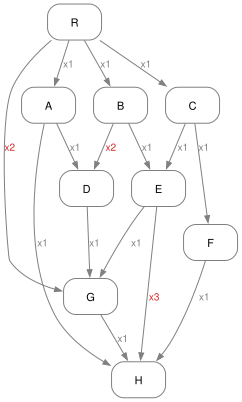

In [ ]:
R, A, B, C, D, E, F, G, H = nodes("R A B C D E F G H")
draw_call_graph(
    {
        R: {A: 1, B: 1, C: 1, G: 2},
        A: {D: 1, H: 1},
        B: {D: 2, E: 1},
        C: {E: 1, F: 1},
        D: {G: 1},
        E: {G: 1, H: 3},
        F: {H: 1},
        G: {H: 1},
        H: {},
    }
)

# Nested subs

Compiled programs whose subs nest several levels deep.

## 8. Grover-style search: shared subs at different depths

`HLayer` is called by the root and by `Diffuser`; `MCZ` by `Oracle` and `Diffuser`. The profile shows only H and Toffoli counts (`gates=`).

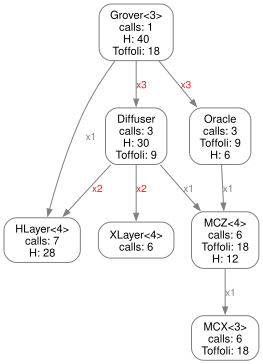

In [ ]:
N = 4


class _HLayer(ParamUnitarySubDef[int]):
    name = "HLayer"

    def qubit_count_fn(self, n: int) -> int:
        return n

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("q", n),)

    def sub(self, b: SubBuilder, n: int) -> None:
        for q in b.qubits:
            b.add_op(std.H, (q,))


HLayer, _ = param_opsub(_HLayer)


class _XLayer(ParamUnitarySubDef[int]):
    name = "XLayer"

    def qubit_count_fn(self, n: int) -> int:
        return n

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("q", n),)

    def sub(self, b: SubBuilder, n: int) -> None:
        for q in b.qubits:
            b.add_op(std.X, (q,))


XLayer, _ = param_opsub(_XLayer)


class _MCX(ParamUnitarySubDef[int]):
    """n-controlled X as a Toffoli V-chain over n - 2 ancillas."""

    name = "MCX"

    def qubit_count_fn(self, n: int) -> int:
        return n + 1 + max(0, n - 2)

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("c", n), QRegSpec("t", 1), QRegSpec("a", max(0, n - 2)))

    def sub(self, b: SubBuilder, n: int) -> None:
        c, a = b.qregs["c"].qubits, b.qregs["a"].qubits
        (t,) = b.qregs["t"].qubits
        if n == 2:
            b.add_op(std.Toffoli, (c[0], c[1], t))
            return
        b.add_op(std.Toffoli, (c[0], c[1], a[0]))
        for i in range(2, n - 1):
            b.add_op(std.Toffoli, (c[i], a[i - 2], a[i - 1]))
        b.add_op(std.Toffoli, (c[n - 1], a[n - 3], t))
        for i in reversed(range(2, n - 1)):
            b.add_op(std.Toffoli, (c[i], a[i - 2], a[i - 1]))
        b.add_op(std.Toffoli, (c[0], c[1], a[0]))


MCX, _ = param_opsub(_MCX)


class _MCZ(ParamUnitarySubDef[int]):
    name = "MCZ"

    def qubit_count_fn(self, n: int) -> int:
        return MCX(n - 1).qubit_count

    def qregs_fn(self, n: int) -> Sequence[QRegSpec]:
        return (QRegSpec("q", MCX(n - 1).qubit_count),)

    def sub(self, b: SubBuilder, n: int) -> None:
        qs = b.qubits
        b.add_op(std.H, (qs[n - 1],))
        b.add_op(MCX(n - 1), qs)
        b.add_op(std.H, (qs[n - 1],))


MCZ, _ = param_opsub(_MCZ)
WIDTH = MCZ(N).qubit_count


class _Oracle(UnitarySubDef):
    name = "Oracle"
    qubit_count = WIDTH

    def sub(self, b: SubBuilder) -> None:
        qs = b.qubits
        b.add_op(std.X, (qs[0],))
        b.add_op(MCZ(N), qs)
        b.add_op(std.X, (qs[0],))


Oracle, _ = opsub(_Oracle)


class _Diffuser(UnitarySubDef):
    name = "Diffuser"
    qubit_count = WIDTH

    def sub(self, b: SubBuilder) -> None:
        qs = b.qubits
        b.add_op(HLayer(N), qs[:N])
        b.add_op(XLayer(N), qs[:N])
        b.add_op(MCZ(N), qs)
        b.add_op(XLayer(N), qs[:N])
        b.add_op(HLayer(N), qs[:N])


Diffuser, _ = opsub(_Diffuser)


class _Grover(ParamUnitarySubDef[int]):
    name = "Grover"

    def qubit_count_fn(self, k: int) -> int:
        return WIDTH

    def qregs_fn(self, k: int) -> Sequence[QRegSpec]:
        return (QRegSpec("q", WIDTH),)

    def sub(self, b: SubBuilder, k: int) -> None:
        qs = b.qubits
        b.add_op(HLayer(N), qs[:N])
        for _ in range(k):
            b.add_op(Oracle, qs)
            b.add_op(Diffuser, qs)


Grover, _ = param_opsub(_Grover)

draw_compiled(Grover(3), (std.X, std.H, std.Toffoli), gates=(std.H, std.Toffoli))

## 9. Controlled nested sub

`Top` calls `Outer` and `Controlled(Outer)`. Controlling a sub creates a controlled node for each sub and gate beneath it. Float params are masked as `*`, so the `RZ` gates with different angles share one `RZ<*>` line.

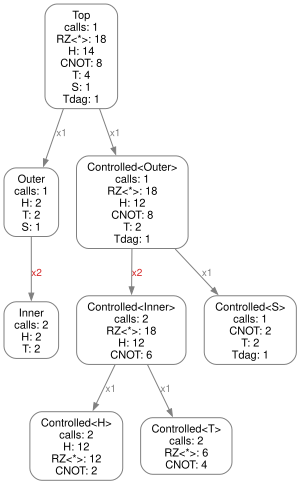

In [ ]:
class _Inner(UnitarySubDef):
    name = "Inner"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(std.H, b.qubits)
        b.add_op(std.T, b.qubits)


Inner, _ = opsub(_Inner)


class _Outer(UnitarySubDef):
    name = "Outer"
    qubit_count = 1

    def sub(self, b: SubBuilder) -> None:
        b.add_op(Inner, b.qubits)
        b.add_op(std.S, b.qubits)
        b.add_op(Inner, b.qubits)


Outer, _ = opsub(_Outer)


class _Top(UnitarySubDef):
    name = "Top"
    qubit_count = 2

    def sub(self, b: SubBuilder) -> None:
        q0, q1 = b.qubits
        b.add_op(Outer, (q1,))
        b.add_op(std.Controlled(Outer), (q0, q1))


Top, _ = opsub(_Top)

clifford_t_rz = (std.X, std.H, std.S, std.Sdag, std.T, std.Tdag, std.CNOT, std.RZ)
draw_compiled(Top, clifford_t_rz)

## 10. Library QPE around a nested unitary

`QPE(3, Outer)` from `quri_parts.qsub.lib.qpe` calls `LineH`, `Controlled(Outer)` (x7 = 1 + 2 + 4) and `QFTdag`.

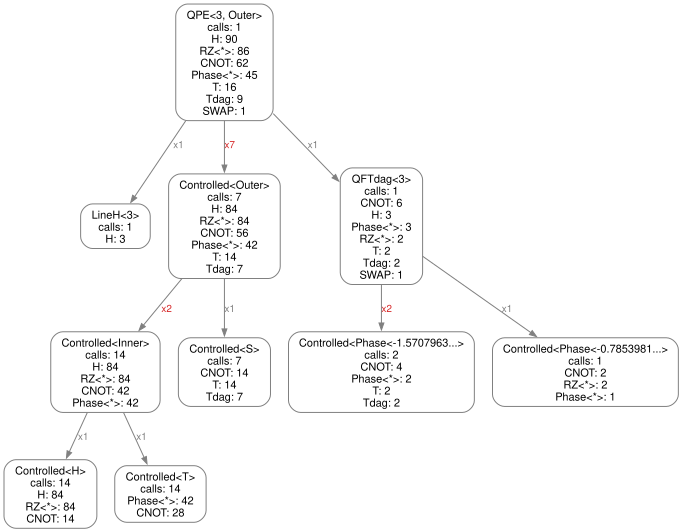

In [ ]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)  # the module is deprecated
    from quri_parts.qsub.lib.qpe import QPE

draw_compiled(QPE(3, Outer), clifford_t_rz + (std.SWAP, std.Phase))